# Гипотезы для задачи прогнозирования зарплаты

Список гипотез, которые можно проверить и превратить в признаки для модели прогнозирования зарплаты. Основа — наблюдения из `eda_salary.ipynb`: 9173 вакансии, зарплаты приведены к USD и году.

Дальше `salary_min` / `salary_max` — это зарплаты в USD за год, таргет — их середина (`midpoint`). Для каждой гипотезы считается p-value, размер эффекта и, где это имеет смысл, прирост качества baseline-модели на кросс-валидации. При n ≈ 9000 почти любое различие значимо, поэтому основной вес — у размера эффекта и MAE, а не у p-value.

Из тестов исключены 18 вакансий с неполной вилкой (заполнен только `salary_min` или только `salary_max`), итоговая выборка — 9155 строк. После каждого блока с кодом стоит вывод: подтвердилась гипотеза или нет и что из этого следует для модели.

Правила проверки:

- сравнение групп — Kruskal–Wallis, пары — Mann–Whitney с поправкой Бонферрони (распределение зарплат не нормальное);
- сила связи — ε² для Kruskal–Wallis, Cramér's V для χ², Spearman для числовых пар;
- вклад в прогноз — 5-fold CV, Ridge на `log(midpoint)`, MAE в логарифмической шкале (≈ средняя относительная ошибка);
- категории с n < 30 в тесты не попадают.

Для запуска нужны `scipy` и `scikit-learn` (в venv проекта они установлены).

In [1]:
import re
import sys
import warnings
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.utils import load_data

RANDOM_STATE = 42

## Подготовка данных

Повторяю нормализацию из EDA: период — к году (час × 2080, день × 260, неделя × 52, месяц × 12), валюта — к USD по фиксированным курсам. Дополнительно считаю производные признаки, которые понадобятся в проверках: середину и ширину вилки, уровень и семейство профессии из `title`, штат США из `location`, признаки пропусков, лаг публикации и флаг подозрительного периода.

In [2]:
PERIOD_COEF = {"day": 260, "week": 52, "month": 12, "hour": 2080, "year": 1}
CURRENCY_PER_USD = {
    "USD": 1.0, "EUR": 0.89, "CAD": 1.42, "GBP": 0.75,
    "AUD": 1.45, "PLN": 3.9, "NZD": 1.78, "CHF": 0.83,
}

SENIORITY_PATTERNS = [
    ("executive", r"\b(head|director|vp|vice president|chief|cfo|ceo|cto|coo|president|founder|partner)\b"),
    ("internship", r"\b(intern|internship|trainee|praktikant)\b"),
    ("senior", r"\b(senior|sr\.?|lead|principal|staff|expert)\b"),
    ("entry", r"\b(entry[- ]level|junior|jr\.?|graduate|apprentice|associate)\b"),
]

FAMILY_PATTERNS = {
    "engineering": r"\b(engineer|developer|programmer|sre|devops|architect|qa|software|frontend|backend|full[- ]stack|mobile|ios|android)\b",
    "data_ai": r"\b(data scien|machine learning|ml |ai |artificial intelligence|analyst|analytics|statistic|research)\b",
    "sales": r"\b(sales|account executive|account manager|business development|bdr|sdr|revenue)\b",
    "marketing": r"\b(marketing|growth|seo|content|brand|social media|communications|copywriter)\b",
    "finance": r"\b(finance|financial|accountant|accounting|controller|auditor|tax|treasury|investment|banking)\b",
    "healthcare": r"\b(nurse|clinical|medical|physician|therapist|pharmac|health|patient|radiolog|surgeon|dental)\b",
    "operations": r"\b(operations|logistics|supply chain|warehouse|production|manufactur|procurement|driver|facilit)\b",
    "hr": r"\b(recruit|talent|human resources|people|hr |compensation|benefits)\b",
    "legal": r"\b(legal|counsel|attorney|lawyer|compliance|paralegal)\b",
    "support": r"\b(customer support|customer success|support specialist|help desk|service desk|call center)\b",
    "product": r"\b(product manager|product owner|project manager|program manager|scrum|product lead)\b",
    "design": r"\b(designer|ux|ui|graphic|creative|art director)\b",
    "education": r"\b(teacher|tutor|instructor|professor|education|curriculum)\b",
}

US_STATES = {
    "alabama": "AL", "alaska": "AK", "arizona": "AZ", "arkansas": "AR", "california": "CA",
    "colorado": "CO", "connecticut": "CT", "delaware": "DE", "florida": "FL", "georgia": "GA",
    "hawaii": "HI", "idaho": "ID", "illinois": "IL", "indiana": "IN", "iowa": "IA",
    "kansas": "KS", "kentucky": "KY", "louisiana": "LA", "maine": "ME", "maryland": "MD",
    "massachusetts": "MA", "michigan": "MI", "minnesota": "MN", "mississippi": "MS",
    "missouri": "MO", "montana": "MT", "nebraska": "NE", "nevada": "NV", "new hampshire": "NH",
    "new jersey": "NJ", "new mexico": "NM", "new york": "NY", "north carolina": "NC",
    "north dakota": "ND", "ohio": "OH", "oklahoma": "OK", "oregon": "OR", "pennsylvania": "PA",
    "rhode island": "RI", "south carolina": "SC", "south dakota": "SD", "tennessee": "TN",
    "texas": "TX", "utah": "UT", "vermont": "VT", "virginia": "VA", "washington": "WA",
    "west virginia": "WV", "wisconsin": "WI", "wyoming": "WY", "district of columbia": "DC",
}
US_STATE_ABBRS = set(US_STATES.values())


def seniority_from_title(title):
    text = str(title).lower()
    for label, pattern in SENIORITY_PATTERNS:
        if re.search(pattern, text):
            return label
    return "mid"


def family_from_title(title):
    text = str(title).lower()
    for label, pattern in FAMILY_PATTERNS.items():
        if re.search(pattern, text):
            return label
    return "other"


def us_state_from_location(row):
    location = str(row["location"]) if pd.notna(row["location"]) else ""
    region = str(row["region"]) if pd.notna(row["region"]) else ""
    for text in (location, region):
        lowered = text.lower()
        for name, abbr in US_STATES.items():
            if name in lowered:
                return abbr
    for text in (location, region):
        match = re.search(r"(?:^|,\s*)([A-Z]{2})(?:\s+\d{5})?\s*$", text)
        if match and match.group(1) in US_STATE_ABBRS:
            return match.group(1)
    return None


def iqr_outlier(values):
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)


raw = load_data()
df = raw.copy()
df["raw_period"] = raw["salary_period"]
df["raw_currency"] = raw["salary_currency"]

period_coef = df["raw_period"].map(PERIOD_COEF)
currency_coef = df["raw_currency"].map(CURRENCY_PER_USD)
df["salary_min"] = df["salary_min"] * period_coef / currency_coef
df["salary_max"] = df["salary_max"] * period_coef / currency_coef

df["midpoint"] = (df["salary_min"] + df["salary_max"]) / 2
df["log_salary"] = np.log(df["midpoint"])
df["log_salary_min"] = np.log(df["salary_min"])
df["log_salary_max"] = np.log(df["salary_max"])
df["spread"] = df["salary_max"] - df["salary_min"]
df["spread_rel"] = df["spread"] / df["midpoint"]

incomplete_salary = df["salary_min"].isna() | df["salary_max"].isna()
print("Строк с неполной вилкой (исключены из тестов):", int(incomplete_salary.sum()))
df = df.loc[~incomplete_salary].reset_index(drop=True)

df["seniority_title"] = df["title"].map(seniority_from_title)
df["family"] = df["title"].map(family_from_title)
df["us_state"] = df.apply(us_state_from_location, axis=1)

df["posted_at"] = pd.to_datetime(df["posted_at"], errors="coerce", utc=True)
df["first_seen_at"] = pd.to_datetime(df["first_seen_at"], errors="coerce", utc=True)
df["posted_month"] = df["posted_at"].dt.month
df["posted_date"] = df["posted_at"].dt.date
df["posted_weekday"] = df["posted_at"].dt.day_name()
df["posting_lag_days"] = (df["first_seen_at"] - df["posted_at"]).dt.total_seconds() / 86400
df["description_len"] = df["description"].str.len()
df["description"] = df["description"].fillna("")
SALARY_MENTION = re.compile(
    r"(?:[$€£]\s?\d[\d,.\s]*(?:k)?|\b\d[\d,.]*\s?(?:usd|eur|gbp|cad|dollars|euros)\b)",
    re.IGNORECASE,
)
df["description_masked"] = df["description"].str.replace(SALARY_MENTION, " [salary] ", regex=True)

for col in ["workplace_type", "seniority", "language", "country_code",
            "employment_type", "department", "region", "city"]:
    df[f"is_missing_{col}"] = df[col].isna()

df["outlier_any"] = iqr_outlier(df["salary_min"]) | iqr_outlier(df["salary_max"])
df["suspicious_period"] = df["raw_period"].ne("year") & (df["salary_min"] > 500_000)

print("Строк:", len(df))
print("Пропуск country_code:", f"{df['country_code'].isna().mean():.1%}")
print("Восстановленный уровень из title:")
print(df["seniority_title"].value_counts().to_string())
print("Штат определён для US-вакансий:", f"{df.loc[df['country_code'] == 'US', 'us_state'].notna().mean():.1%}")
print("Подозрительный период:", int(df["suspicious_period"].sum()), "строк")
display(df[["title", "salary_min", "salary_max", "midpoint", "raw_period",
            "seniority_title", "family", "us_state"]].head())

Строк с неполной вилкой (исключены из тестов): 18


Строк: 9155
Пропуск country_code: 12.3%
Восстановленный уровень из title:
seniority_title
mid           5716
senior        1953
executive      864
entry          480
internship     142
Штат определён для US-вакансий: 73.2%
Подозрительный период: 20 строк


,title,salary_min,salary_max,midpoint,raw_period,seniority_title,family,us_state
0,"Instrument Engineer, On Call",90000.000000,340000.000000,215000.000000,year,mid,engineering,CA
1,Content Coordinator,55172.413793,62068.965517,58620.689655,year,mid,marketing,NaN
2,Senior Cyber Security Engineer - Identity and ...,160000.000000,240000.000000,200000.000000,year,senior,engineering,CA
3,"Vice President, Global Accounting",213030.000000,286670.000000,249850.000000,year,executive,finance,NaN
4,Platform Engineer - Workspace,72072.137931,78082.365517,75077.251724,year,mid,engineering,NaN


### Тесты и модель

`epsilon2` — доля дисперсии рангов, объяснённая группой (0.01 — слабый эффект, 0.06 — средний, 0.14 — сильный). Модель — Ridge на `log(midpoint)` с one-hot категориями; MAE в лог-шкале 0.30 означает среднюю ошибку около 35% (`exp(0.30) − 1`). Все сравнения моделей идут на одних и тех же 5 фолдах.

In [3]:
MISSING_LABEL = "(нет данных)"
MIN_GROUP_SIZE = 30


def format_p(p):
    return "< 0.001" if p < 0.001 else f"{p:.3f}"


def group_stats(data, column, value="midpoint", min_n=MIN_GROUP_SIZE, decimals=0):
    prepared = data.copy()
    prepared[column] = prepared[column].fillna(MISSING_LABEL)
    table = (
        prepared.groupby(column)[value]
        .agg(n="size", median="median",
             q1=lambda s: s.quantile(0.25),
             q3=lambda s: s.quantile(0.75))
        .query("n >= @min_n")
        .sort_values("median", ascending=False)
    )
    overall = data[value].median()
    table["median_vs_all"] = table["median"] / overall
    table[["median", "q1", "q3"]] = table[["median", "q1", "q3"]].round(decimals)
    table["median_vs_all"] = table["median_vs_all"].round(2)
    return table


def kruskal_test(data, column, value="log_salary", min_n=MIN_GROUP_SIZE):
    groups = {}
    for name, part in data.groupby(data[column].fillna(MISSING_LABEL)):
        values = part[value].dropna()
        if len(values) >= min_n:
            groups[name] = values
    h, p = stats.kruskal(*groups.values())
    n = sum(len(values) for values in groups.values())
    k = len(groups)
    epsilon2 = (h - k + 1) / (n - k)
    return pd.Series({
        "H": h, "p": p, "epsilon2": epsilon2,
        "groups": k, "n": n,
        "min_group_n": min(len(values) for values in groups.values()),
    })


def pairwise_tests(data, column, value="log_salary", min_n=MIN_GROUP_SIZE, alternative="two-sided"):
    groups = {}
    for name, part in data.groupby(data[column].fillna(MISSING_LABEL)):
        values = part[value].dropna()
        if len(values) >= min_n:
            groups[name] = values

    rows = []
    for first, second in combinations(groups, 2):
        _, p = stats.mannwhitneyu(groups[first], groups[second], alternative=alternative)
        rows.append({
            "группа A": first, "группа B": second,
            "медиана A, USD": np.exp(groups[first].median()),
            "медиана B, USD": np.exp(groups[second].median()),
            "p": p,
        })
    result = pd.DataFrame(rows)
    result["p_adj"] = (result["p"] * len(result)).clip(upper=1)
    result[["медиана A, USD", "медиана B, USD"]] = result[["медиана A, USD", "медиана B, USD"]].round(0)
    return result.sort_values("p")


def chi2_test(data, first, second):
    table = pd.crosstab(data[first].fillna(MISSING_LABEL), data[second].fillna(MISSING_LABEL))
    chi2, p, dof, _ = stats.chi2_contingency(table)
    n = table.values.sum()
    cramers_v = np.sqrt(chi2 / (n * (min(table.shape) - 1)))
    return pd.Series({"chi2": chi2, "p": p, "dof": dof,
                      "cramers_v": cramers_v, "n": n})


def median_test(data, mask, value="midpoint"):
    first, second = data.loc[mask, value], data.loc[~mask, value]
    _, p = stats.mannwhitneyu(first, second)
    return pd.Series({
        "n группы": int(mask.sum()),
        "медиана группы": first.median(),
        "медиана остальных": second.median(),
        "p": p,
    })


def describe_test(result):
    frame = result.to_frame().T
    frame["p"] = frame["p"].map(format_p)
    for column, digits in [("H", 2), ("chi2", 2), ("epsilon2", 3), ("cramers_v", 3),
                           ("dof", 0), ("n", 0), ("groups", 0), ("min_group_n", 0),
                           ("n группы", 0), ("медиана группы", 0), ("медиана остальных", 0)]:
        if column in frame:
            frame[column] = frame[column].astype(float).round(digits)
    return frame


CORE_CAT = ["ats", "employment_type", "country_code", "salary_source"]
CORE_NUM = [
    "is_missing_workplace_type", "is_missing_seniority", "is_missing_language",
    "is_missing_country_code", "is_missing_employment_type", "is_missing_department",
    "description_len", "posted_month", "posting_lag_days", "outlier_any",
]


def features(add_cat=(), add_num=(), drop_cat=()):
    return (
        [column for column in CORE_CAT if column not in drop_cat] + list(add_cat),
        CORE_NUM + list(add_num),
    )


def make_pipeline(cat_columns, num_columns, alpha=1.0):
    return Pipeline([
        ("prep", ColumnTransformer([
            ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20), cat_columns),
            ("num", StandardScaler(), num_columns),
        ])),
        ("model", Ridge(alpha=alpha)),
    ])


def cv_oof(data, target, cat_columns, num_columns, n_splits=5):
    folds = KFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
    predictions = pd.Series(index=data.index, dtype=float)
    for train_idx, valid_idx in folds.split(data):
        pipeline = make_pipeline(cat_columns, num_columns)
        pipeline.fit(data.iloc[train_idx], target.iloc[train_idx])
        predictions.iloc[valid_idx] = pipeline.predict(data.iloc[valid_idx])
    return predictions


def cv_metrics(predictions, target):
    return pd.Series({
        "MAE (log)": mean_absolute_error(target, predictions),
        "RMSE (log)": mean_squared_error(target, predictions) ** 0.5,
        "R2": r2_score(target, predictions),
    })


def cv_table(data, target, variants, n_splits=5):
    rows = {}
    for label, (cat_columns, num_columns) in variants.items():
        predictions = cv_oof(data, target, cat_columns, num_columns, n_splits=n_splits)
        rows[label] = cv_metrics(predictions, target)
    return pd.DataFrame(rows).T.round(3)


def target_encode(train, valid, column, target, smoothing=20):
    prior = target.mean()
    frame = pd.DataFrame({"key": train[column].astype(str), "y": target.to_numpy()})
    grouped = frame.groupby("key")["y"].agg(["mean", "count"])
    mapping = (grouped["mean"] * grouped["count"] + prior * smoothing) / (grouped["count"] + smoothing)
    return (
        train[column].astype(str).map(mapping).fillna(prior),
        valid[column].astype(str).map(mapping).fillna(prior),
    )


def cv_with_target_encoding(data, target, cat_columns, num_columns, te_columns, smoothing=20, n_splits=5):
    folds = KFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
    predictions = pd.Series(index=data.index, dtype=float)
    for train_idx, valid_idx in folds.split(data):
        train, valid = data.iloc[train_idx].copy(), data.iloc[valid_idx].copy()
        encoded_columns = []
        for column in te_columns:
            train[f"{column}_te"], valid[f"{column}_te"] = target_encode(
                train, valid, column, target.iloc[train_idx], smoothing
            )
            encoded_columns.append(f"{column}_te")
        pipeline = make_pipeline(cat_columns, num_columns + encoded_columns)
        pipeline.fit(train, target.iloc[train_idx])
        predictions.iloc[valid_idx] = pipeline.predict(valid)
    return predictions

## 1. Таргет: логарифм зарплаты

**1. Предсказывать логарифм зарплаты, а не саму зарплату.**
Распределение сильно смещено вправо (skew ≈ 3.8), медиана 85 000 против максимума 1 168 539. Проверяю асимметрию до и после логарифма, нормальность и качество модели на двух таргетах.

,skew,kurtosis,mean / median
зарплата,3.56,32.38,1.17
log(зарплата),-0.08,0.02,1.00


Д'Агостино, зарплата: p = 0.00e+00
Д'Агостино, log(зарплата): p = 4.75e-03


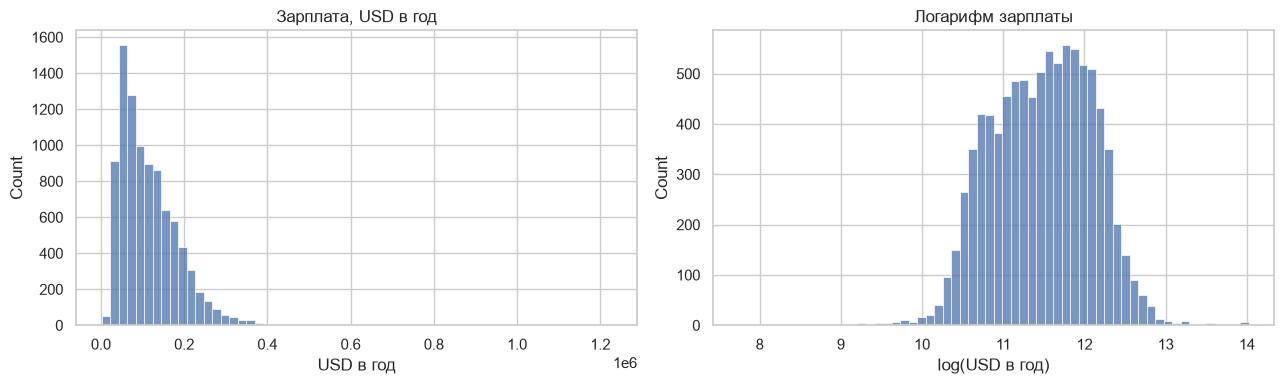

,"MAE, USD","RMSE, USD",RMSLE
модель на зарплате,39715.564,56979.375,0.534
модель на логарифме,39727.272,62220.021,0.452


In [4]:
salary = df["midpoint"]
log_salary = df["log_salary"]

normality = pd.DataFrame({
    "skew": [salary.skew(), log_salary.skew()],
    "kurtosis": [salary.kurt(), log_salary.kurt()],
    "mean / median": [salary.mean() / salary.median(), log_salary.mean() / log_salary.median()],
}, index=["зарплата", "log(зарплата)"])
display(normality.round(2))

for values, label in [(salary, "зарплата"), (log_salary, "log(зарплата)")]:
    stat, p = stats.normaltest(values)
    print(f"Д'Агостино, {label}: p = {p:.2e}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(salary, bins=60, ax=axes[0])
axes[0].set_title("Зарплата, USD в год")
axes[0].set_xlabel("USD в год")
sns.histplot(log_salary, bins=60, ax=axes[1])
axes[1].set_title("Логарифм зарплаты")
axes[1].set_xlabel("log(USD в год)")
plt.tight_layout()
plt.show()

cat_columns, num_columns = features(add_cat=["workplace_type", "family"])
pred_raw = cv_oof(df, df["midpoint"], cat_columns, num_columns)
pred_log = cv_oof(df, df["log_salary"], cat_columns, num_columns)
pred_log_usd = np.exp(pred_log)


def usd_metrics(predictions, actual):
    predictions = np.clip(predictions, 1, None)
    return pd.Series({
        "MAE, USD": mean_absolute_error(actual, predictions),
        "RMSE, USD": mean_squared_error(actual, predictions) ** 0.5,
        "RMSLE": np.sqrt(np.mean((np.log1p(predictions) - np.log1p(actual)) ** 2)),
    })


target_comparison = pd.DataFrame({
    "модель на зарплате": usd_metrics(pred_raw, df["midpoint"]),
    "модель на логарифме": usd_metrics(pred_log_usd, df["midpoint"]),
}).T.round(3)
display(target_comparison)

### Вывод по гипотезе 1

Гипотеза подтверждается. Логарифм убирает асимметрию: skew падает с 3.56 до −0.08, эксцесс — с 32.4 до 0.02, отношение среднего к медиане становится 1.00. Формальный тест Д'Агостино всё ещё отвергает нормальность для логарифма (p = 0.005), но при n = 9155 он чувствителен к небольшим отклонениям, а распределение визуально близко к нормальному.

На кросс-валидации модели на сырой зарплате и на логарифме дают практически одинаковую абсолютную ошибку в долларах (39 716 против 39 727), но RMSLE у логарифма ниже на 15%: 0.452 против 0.534. То есть логарифм лучше предсказывает относительные ошибки и хвост дорогих вакансий, не проигрывая в MAE. Для задачи прогнозирования зарплаты это правильный таргет.

## 2-3. Структура вилки

**2. Предсказывать середину диапазона, а не min и max по отдельности.**
`salary_min` и `salary_max` почти линейно связаны (Pearson 0.944 / Spearman 0.958), поэтому одного таргета достаточно, а границы можно восстанавливать.

**3. Ширина вилки (`max − min`) — отдельный сигнал.**
У senior-офисных вакансий вилки шире, у почасовых — узкие. Можно рассматривать как второй таргет.

,Pearson,Spearman
salary_min vs salary_max,0.944,0.958
spread_rel vs midpoint,0.152,0.236


Линейная регрессия max ~ min: R2 = 0.892, коэффициент = 1.271
Медианная относительная ошибка восстановления max: 13.0%
Доля вакансий с max = min: 2.4%


count    9155.000
mean        0.259
std         0.176
min         0.000
10%         0.079
50%         0.222
90%         0.487
max         1.754
Name: spread_rel, dtype: float64

,n,median,q1,q3,median_vs_all
seniority_title,,,,,
senior,1953,0.250,0.162,0.378,1.12
internship,142,0.222,0.118,0.462,1.00
mid,5716,0.222,0.128,0.338,1.00
executive,864,0.222,0.143,0.333,1.00
entry,480,0.211,0.116,0.330,0.95


,n,median,q1,q3,median_vs_all
raw_period,,,,,
month,265,0.279,0.154,0.377,1.26
year,6634,0.228,0.154,0.366,1.03
hour,2239,0.169,0.091,0.287,0.76


,H,p,epsilon2,groups,n,min_group_n
по уровню,93.405,< 0.001,0.010,5.0,9155.0,142.0
по периоду,335.088,< 0.001,0.036,3.0,9138.0,265.0
по ats,270.403,< 0.001,0.029,8.0,9124.0,75.0


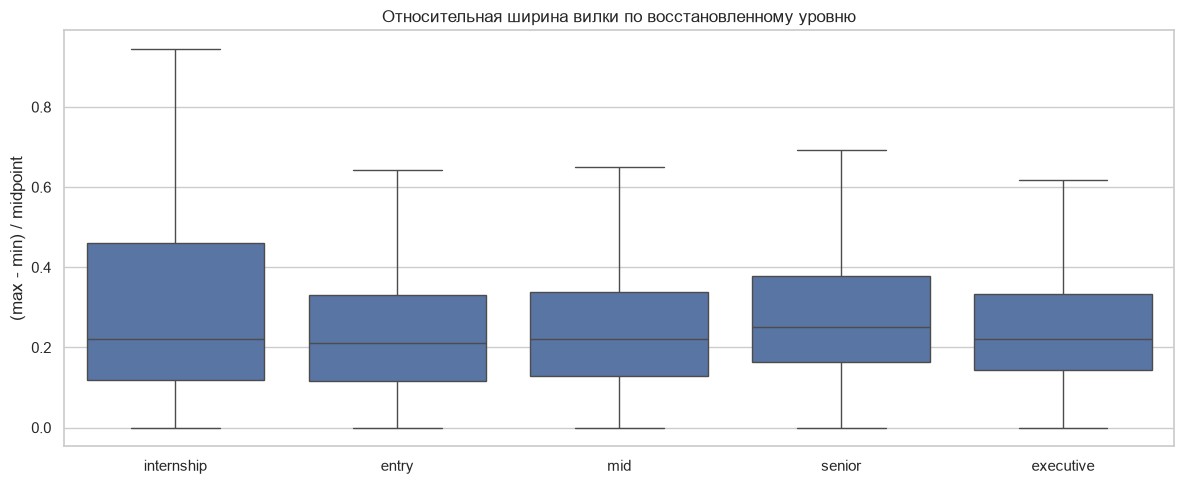

In [5]:
correlation = pd.DataFrame({
    "Pearson": [df["salary_min"].corr(df["salary_max"]), df["spread_rel"].corr(df["midpoint"])],
    "Spearman": [df["salary_min"].corr(df["salary_max"], method="spearman"),
                 df["spread_rel"].corr(df["midpoint"], method="spearman")],
}, index=["salary_min vs salary_max", "spread_rel vs midpoint"])
display(correlation.round(3))

linear = LinearRegression().fit(df[["salary_min"]], df["salary_max"])
predicted_max = linear.predict(df[["salary_min"]])
print(f"Линейная регрессия max ~ min: R2 = {linear.score(df[['salary_min']], df['salary_max']):.3f}, "
      f"коэффициент = {linear.coef_[0]:.3f}")
print(f"Медианная относительная ошибка восстановления max: "
      f"{np.median(np.abs(predicted_max - df['salary_max']) / df['salary_max']):.1%}")
print(f"Доля вакансий с max = min: {(df['salary_max'] == df['salary_min']).mean():.1%}")

display(df["spread_rel"].describe(percentiles=[0.1, 0.5, 0.9]).round(3))
display(group_stats(df, "seniority_title", value="spread_rel", decimals=3))
display(group_stats(df, "raw_period", value="spread_rel", decimals=3))
spread_tests = pd.DataFrame({
    "по уровню": kruskal_test(df, "seniority_title", value="spread_rel"),
    "по периоду": kruskal_test(df, "raw_period", value="spread_rel"),
    "по ats": kruskal_test(df, "ats", value="spread_rel"),
}).T
spread_tests["p"] = spread_tests["p"].map(format_p)
display(spread_tests.round(3))


sns.boxplot(data=df, x="seniority_title", y="spread_rel", showfliers=False,
            order=["internship", "entry", "mid", "senior", "executive"])
plt.title("Относительная ширина вилки по восстановленному уровню")
plt.ylabel("(max - min) / midpoint")
plt.xlabel("")
plt.tight_layout()
plt.show()

### Выводы по гипотезам 2-3

**Гипотеза 2 подтверждается.** `salary_min` и `salary_max` связаны почти линейно (Pearson 0.944, Spearman 0.958), линейная регрессия `max ~ min` даёт R² = 0.892, а медианная относительная ошибка восстановления максимума — 13.0%. Только 2.4% вакансий имеют фиксированную вилку (`max = min`). Одного таргета `midpoint` достаточно; при необходимости границы восстанавливаются из него с ошибкой порядка 10-15%.

**Гипотеза 3 подтверждается частично.** Ширина вилки — отдельный, но слабый сигнал. Медианная относительная ширина 0.222 (10-й процентиль 0.079, 90-й — 0.487), и она слабо растёт с зарплатой (Spearman 0.236). Различия по группам значимы, но эффекты небольшие: по уровню ε² = 0.010, по `ats` — 0.029, по исходному периоду — 0.036. Направление ожидаемое: у почасовых вилка уже (0.169), у годовых и месячных шире (0.228 и 0.279); у senior вилка шире, чем у entry (0.250 против 0.211), но у executive и mid разницы нет. Как второй таргет ширина годится, как сильный признак — нет.

## 4-7. Роль и уровень позиции

**4. Уровень позиции положительно влияет на зарплату.**
Уже видно: executive 100 000 > senior 83 200 > mid 50 711 > entry 44 860. Проверка — Kruskal–Wallis.

**5. Уровень можно восстановить из `title`, несмотря на 93% пропусков в `seniority`.**
Слова senior / lead / head / director / VP / intern и упоминания стажа в описании дают сигнал. Проверка: сравнить зарплаты групп, собранных регулярками, и прирост качества модели с новым признаком.

**6. Семейство профессии значимо.**
`title` слишком гранулярен (8044 значения), но семейства (engineering, sales, healthcare, finance, marketing, ops) различаются по вилкам. Ключевая гипотеза для сильного признака: агрегация, кластеризация или токенизация title.

**7. `department` полезен там, где заполнен (59%).**
Проверять прирост качества на подвыборке, где поле есть.

,n,median,q1,q3,median_vs_all
seniority,,,,,
executive,23,135000.0,82750.0,172000.0,1.36
(нет данных),8543,102500.0,62400.0,159500.0,1.03
senior,209,97500.0,63380.0,140000.0,0.98
mid,99,61620.0,46743.0,76124.0,0.62
entry,268,50062.0,39325.0,72858.0,0.50


,H,p,epsilon2,groups,n,min_group_n
0,298.52,< 0.001,0.032,5.0,9142.0,23.0


,группа A,группа B,"медиана A, USD","медиана B, USD",p,p_adj
0,(нет данных),entry,102500.0,50062.0,2.000581e-53,2.000581e-52
6,entry,senior,50062.0,97500.0,2.926834e-23,2.926834e-22
2,(нет данных),mid,102500.0,61620.0,2.509144e-15,2.509144e-14
9,mid,senior,61620.0,97500.0,5.173241e-10,5.173241e-09
4,entry,executive,50062.0,135000.0,4.115711e-07,4.115711e-06
7,executive,mid,135000.0,61620.0,1.362963e-05,1.362963e-04
5,entry,mid,50062.0,61620.0,4.044343e-03,4.044343e-02
3,(нет данных),senior,102500.0,97500.0,1.122257e-01,1.000000e+00
8,executive,senior,135000.0,97500.0,1.235332e-01,1.000000e+00
1,(нет данных),executive,102500.0,135000.0,3.206222e-01,1.000000e+00


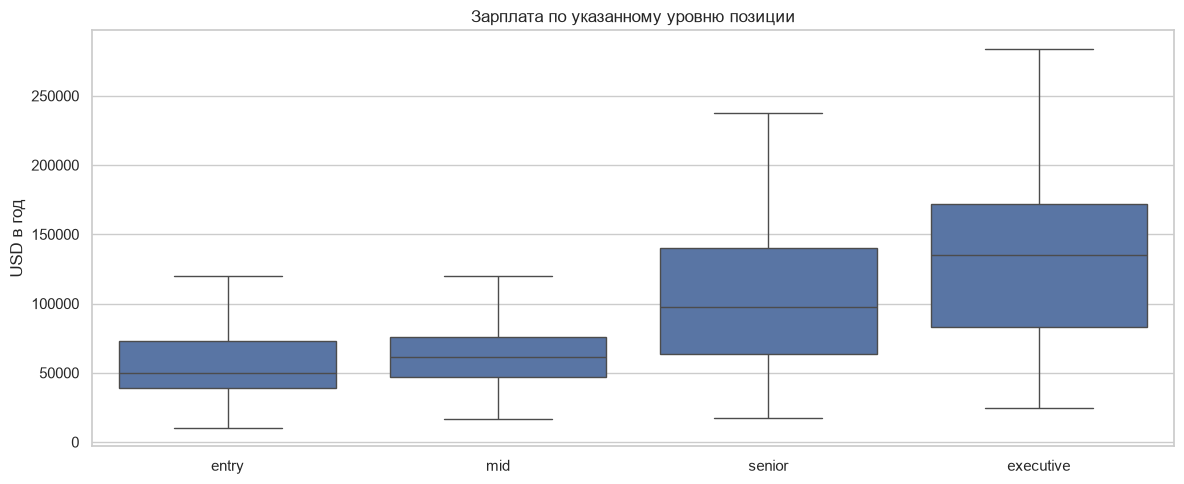

In [6]:
display(group_stats(df, "seniority", min_n=20))
display(kruskal_test(df, "seniority", min_n=20).pipe(describe_test))
display(pairwise_tests(df, "seniority", min_n=20))

sns.boxplot(data=df[df["seniority"].notna()], x="seniority", y="midpoint", showfliers=False,
            order=["entry", "mid", "senior", "executive"])
plt.title("Зарплата по указанному уровню позиции")
plt.xlabel("")
plt.ylabel("USD в год")
plt.tight_layout()
plt.show()

### Вывод по гипотезе 4

Гипотеза подтверждается, но эффект умеренный. Медианы: executive 135 000 (n = 23), senior 97 500 (n = 209), mid 61 620 (n = 99), entry 50 062 (n = 268). Kruskal–Wallis: H = 298.5, p < 0.001, ε² = 0.032. Попарно entry значимо ниже mid и senior, senior значимо выше mid; executive и senior между собой не различаются (p_adj = 1.0) — на 23 наблюдениях это ожидаемо.

Важнее другое: группа «нет данных» (8543 строки, 93%) имеет медиану 102 500 и не отличается от senior/executive. Пропуск уровня — не случайное отсутствие, а отдельный сегмент рынка, и трактовать его как обычный NaN нельзя.

In [7]:
labeled = df[df["seniority"].notna()].copy()
accuracy = (labeled["seniority"] == labeled["seniority_title"]).mean()
print(f"Точность восстановления уровня по title на размеченных строках: {accuracy:.1%}, "
      f"размечено {len(labeled)} из {len(df)}")
display(pd.crosstab(labeled["seniority"], labeled["seniority_title"], normalize="index").round(2))

recovered_share = (df["seniority_title"] != "mid").mean()
print(f"Доля вакансий, где регулярка выделила явный уровень: {recovered_share:.1%}")
display(group_stats(df, "seniority_title"))
display(kruskal_test(df, "seniority_title").pipe(describe_test))

display(cv_table(df, df["log_salary"], {
    "без уровня": features(),
    "seniority из данных": features(add_cat=["seniority"]),
    "уровень из title": features(add_cat=["seniority_title"]),
    "оба признака": features(add_cat=["seniority", "seniority_title"]),
}))

Точность восстановления уровня по title на размеченных строках: 28.8%, размечено 612 из 9155


seniority_title,entry,executive,internship,mid,senior
seniority,,,,,
entry,0.12,0.03,0.01,0.79,0.06
executive,0.00,0.65,0.00,0.26,0.09
internship,0.00,0.00,0.23,0.77,0.00
mid,0.02,0.01,0.00,0.82,0.15
senior,0.02,0.05,0.00,0.70,0.22


Доля вакансий, где регулярка выделила явный уровень: 37.6%


,n,median,q1,q3,median_vs_all
seniority_title,,,,,
executive,864,180547.0,137500.0,232625.0,1.81
senior,1953,145000.0,103500.0,190000.0,1.46
mid,5716,80050.0,52719.0,125000.0,0.80
entry,480,64860.0,43789.0,91221.0,0.65
internship,142,54080.0,46800.0,71370.0,0.54


,H,p,epsilon2,groups,n,min_group_n
0,2211.77,< 0.001,0.241,5.0,9155.0,142.0


,MAE (log),RMSE (log),R2
без уровня,0.389,0.479,0.404
seniority из данных,0.386,0.477,0.411
уровень из title,0.348,0.438,0.502
оба признака,0.346,0.436,0.506


### Вывод по гипотезе 5

Гипотеза подтверждается практически, но не буквально. Точное совпадение с размеченным `seniority` — всего 28.8% на 612 строках: регулярка уверенно ловит executive (65% recall) и mid (82%), но senior — только 22%, entry — 12%, потому что уровень часто не назван в заголовке. Зато там, где регулярка выделила уровень (37.6% всех вакансий), группы разделяются по зарплате очень сильно: executive 180 547, senior 145 000, mid 80 050, entry 64 860, internship 54 080, ε² = 0.241.

Для модели это важнее точности метки: признак `seniority_title` улучшает MAE с 0.389 до 0.348 (−10.5%), тогда как исходный `seniority` — только до 0.386 (−0.8%), а вместе они дают 0.346. Иными словами, грубая группировка из title полезнее, чем почти пустое исходное поле. Использовать её стоит как порядковый/категориальный признак, но не как замену ручной разметке.

In [8]:
display(group_stats(df, "family"))
display(kruskal_test(df, "family").pipe(describe_test))
display(cv_table(df, df["log_salary"], {
    "без семейства": features(),
    "с семейством": features(add_cat=["family"]),
}))

,n,median,q1,q3,median_vs_all
family,,,,,
legal,153,166667.0,105450.0,212750.0,1.68
engineering,1393,150000.0,110240.0,192500.0,1.51
product,277,145000.0,108600.0,184100.0,1.46
marketing,354,123250.0,81633.0,174825.0,1.24
hr,162,119708.0,77750.0,167250.0,1.20
design,89,119000.0,80000.0,165000.0,1.20
finance,256,115000.0,69844.0,150000.0,1.16
data_ai,504,103661.0,74688.0,140000.0,1.04
sales,848,102800.0,63425.0,157500.0,1.03


,H,p,epsilon2,groups,n,min_group_n
0,1351.24,< 0.001,0.146,14.0,9155.0,89.0


,MAE (log),RMSE (log),R2
без семейства,0.389,0.479,0.404
с семейством,0.362,0.454,0.467


### Вывод по гипотезе 6

Гипотеза подтверждается. Семейства профессий различаются заметно: legal 166 667, engineering 150 000, product 145 000, marketing 123 250, finance 115 000, data_ai 103 661, sales 102 800, healthcare 93 417, operations 84 483, education 62 000; Kruskal–Wallis ε² = 0.146. Признак `family` снижает MAE с 0.389 до 0.362 (−7%).

Ограничение: 43% заголовков попадают в `other` — регулярки покрывают не все профессии, и внутри `other` остаются разнородные роли с медианой 73 492. Это резерв для улучшения: расширение словаря, кластеризация или токенизация title должны добавить сигнала.

In [9]:
department_data = df[df["department"].notna()].copy()
department_counts = department_data["department"].value_counts()
department_data["department_group"] = department_data["department"].where(
    department_data["department"].map(department_counts) >= MIN_GROUP_SIZE, "other"
)
print(f"Подвыборка с department: {len(department_data)} строк, "
      f"{department_data['department_group'].nunique()} групп после укрупнения")

display(group_stats(department_data, "department_group"))
display(kruskal_test(department_data, "department_group").pipe(describe_test))
display(cv_table(department_data, department_data["log_salary"], {
    "без department": features(),
    "с department": features(add_cat=["department_group"]),
}))

Подвыборка с department: 5400 строк, 18 групп после укрупнения


,n,median,q1,q3,median_vs_all
department_group,,,,,
Engineering,374,185125.0,145000.0,219375.0,1.61
Product,93,183468.0,135000.0,214000.0,1.60
Legal,44,173250.0,135000.0,226875.0,1.51
GTM,33,162500.0,110000.0,215000.0,1.41
Growth,33,155000.0,110000.0,195000.0,1.35
People,46,150000.0,130000.0,174912.0,1.30
Sales,248,140000.0,82500.0,200000.0,1.22
Finance,91,137500.0,95126.0,174000.0,1.20
Marketing,157,135000.0,102500.0,175000.0,1.17


,H,p,epsilon2,groups,n,min_group_n
0,583.93,< 0.001,0.105,18.0,5400.0,30.0


,MAE (log),RMSE (log),R2
без department,0.397,0.489,0.395
с department,0.382,0.473,0.433


### Вывод по гипотезе 7

Гипотеза подтверждается на подвыборке с заполненным полем. 5400 строк, 18 укрупнённых отделов: engineering 185 125, product 183 468, legal 173 250, sales 140 000, …, operations 90 000, retail 39 000; ε² = 0.105. Признак `department_group` снижает MAE на этой подвыборке с 0.397 до 0.382 (−3.8%).

Поле полезно, но это во многом дублирование семейства профессий, и 41% строк его не имеют. Разумная стратегия — использовать `department` там, где он есть, плюс отдельный индикатор пропуска, а основным сигналом о роли оставить title.

## 8-11. География и формат работы

**8. `country_code` значимо влияет на зарплату.**
США 90 000 против Франции и Италии ~36 000 (без поправки на паритет покупательной способности).

**9. Формат работы: remote > hybrid > onsite.**
110 000 / 100 000 / 66 667. Отдельно проверить, не объясняется ли это тем, что remote-вакансии чаще из tech-компаний (контроль на `ats` и роль).

**10. Внутри США город и штат значимы.**
`city` и `region` заполнены на 24–26%, но их можно извлекать из `location` (99.9%) и из `title`. Проверка: медианы по извлечённым штатам и прирост качества.

**11. `country_code` «нет данных» — не случайный пропуск, а сигнал.**
У группы без страны медиана 110 000, выше, чем у США. Гипотеза: такой пропуск связан с remote-вакансиями крупных компаний.

In [10]:
display(group_stats(df, "country_code"))
display(kruskal_test(df, "country_code").pipe(describe_test))

top_countries = group_stats(df, "country_code").head(8).index
display(pairwise_tests(df[df["country_code"].isin(top_countries)], "country_code"))

display(cv_table(df, df["log_salary"], {
    "без страны": features(drop_cat=["country_code"]),
    "со страной": features(),
}))

,n,median,q1,q3,median_vs_all
country_code,,,,,
(нет данных),1122,129300.0,79363.0,179000.0,1.30
US,6619,107500.0,65811.0,162500.0,1.08
DE,70,78933.0,48739.0,118090.0,0.79
AU,54,76363.0,66179.0,87969.0,0.77
GB,240,68406.0,47853.0,110000.0,0.69
CA,538,61620.0,42395.0,87500.0,0.62
NL,101,60674.0,46760.0,74157.0,0.61
IT,77,44494.0,34831.0,58989.0,0.45
FR,98,40338.0,30478.0,61236.0,0.41


,H,p,epsilon2,groups,n,min_group_n
0,830.58,< 0.001,0.092,9.0,8919.0,54.0


,группа A,группа B,"медиана A, USD","медиана B, USD",p,p_adj
10,CA,US,61620.0,107500.0,3.171139e-81,6.659392e-80
19,IT,US,44494.0,107500.0,2.358056e-25,4.951919e-24
20,NL,US,60674.0,107500.0,2.475134e-19,5.197782e-18
17,GB,US,68388.0,107500.0,6.490523e-18,1.363010e-16
3,AU,IT,76362.0,44494.0,3.173383e-12,6.664104e-11
15,GB,IT,68388.0,44494.0,3.819023e-10,8.019948e-09
8,CA,IT,61620.0,44494.0,6.084638e-07,1.277774e-05
12,DE,IT,78892.0,44494.0,8.818268e-07,1.851836e-05
18,IT,NL,44494.0,60674.0,2.102787e-06,4.415853e-05
4,AU,NL,76362.0,60674.0,6.187654e-06,1.299407e-04


,MAE (log),RMSE (log),R2
без страны,0.408,0.502,0.347
со страной,0.389,0.479,0.404


### Вывод по гипотезе 8

Гипотеза подтверждается. Медианы: «нет данных» 129 300, US 107 500, DE 78 933, AU 76 363, GB 68 406, CA 61 620, NL 60 674, IT 44 494, FR 40 338. Kruskal–Wallis ε² = 0.092, попарно US значимо выше CA, IT, NL и GB. Признак страны снижает MAE с 0.408 до 0.389 (−4.7%).

Интерпретировать разрывы как «зарплату за одну и ту же работу» нельзя: не учтены паритет покупательной способности, налоги и структура вакансий. Но для модели страна — дешёвый и устойчивый признак, а группа без страны снова оказывается самой дорогой.

In [11]:
display(group_stats(df, "workplace_type"))
display(kruskal_test(df, "workplace_type").pipe(describe_test))
display(pairwise_tests(df, "workplace_type"))

workplace_values = {
    name: part["log_salary"].dropna()
    for name, part in df.groupby("workplace_type")
}
print("Односторонние проверки (A > B):")
for first, second in [("remote", "onsite"), ("hybrid", "onsite"), ("remote", "hybrid")]:
    _, p = stats.mannwhitneyu(workplace_values[first], workplace_values[second], alternative="greater")
    print(f"  {first} > {second}: p = {format_p(p)}")

control_cat = ["ats", "family", "country_code", "employment_type", "seniority_title", "workplace_type"]
control_pipeline = make_pipeline(control_cat, CORE_NUM)
control_pipeline.fit(df[control_cat + CORE_NUM], df["log_salary"])
control_names = control_pipeline.named_steps["prep"].get_feature_names_out()
control_coefs = pd.Series(control_pipeline.named_steps["model"].coef_, index=control_names)
workplace_coefs = control_coefs[control_coefs.index.str.startswith("cat__workplace_type_")]
baseline = workplace_coefs.get("cat__workplace_type_onsite", 0.0)
print("Эффект формата работы при контроле на ats, семейство, страну, занятость и уровень:")
display(pd.DataFrame({
    "коэффициент (log)": workplace_coefs,
    "эффект к onsite, %": (np.exp(workplace_coefs - baseline) - 1) * 100,
}).round(2))

for label, subset in [
    ("engineering", df[df["family"] == "engineering"]),
    ("US", df[df["country_code"] == "US"]),
    ("ashby", df[df["ats"] == "ashby"]),
]:
    medians = subset.groupby("workplace_type")["midpoint"].median().round(0)
    counts = subset["workplace_type"].value_counts()
    print(f"\n{label} (n={len(subset)}):")
    display(pd.DataFrame({"n": counts, "медиана": medians}).dropna())

,n,median,q1,q3,median_vs_all
workplace_type,,,,,
remote,1730,130000.0,87395.0,176389.0,1.31
hybrid,1024,117575.0,76667.0,180000.0,1.18
(нет данных),5147,88850.0,56113.0,140000.0,0.89
onsite,1254,76960.0,47889.0,145000.0,0.77


,H,p,epsilon2,groups,n,min_group_n
0,505.96,< 0.001,0.055,4.0,9155.0,1024.0


,группа A,группа B,"медиана A, USD","медиана B, USD",p,p_adj
2,(нет данных),remote,88850.0,130000.0,4.475521e-81,2.685313e-80
5,onsite,remote,76960.0,130000.0,1.159602e-57,6.957613e-57
0,(нет данных),hybrid,88850.0,117575.0,4.156012e-34,2.493607e-33
3,hybrid,onsite,117575.0,76960.0,4.117069e-33,2.470241e-32
1,(нет данных),onsite,88850.0,76960.0,2.548061e-05,1.528836e-04
4,hybrid,remote,117575.0,130000.0,1.095749e-02,6.574496e-02


Односторонние проверки (A > B):
  remote > onsite: p = < 0.001
  hybrid > onsite: p = < 0.001
  remote > hybrid: p = 0.005
Эффект формата работы при контроле на ats, семейство, страну, занятость и уровень:


,коэффициент (log),"эффект к onsite, %"
cat__workplace_type_hybrid,0.04,9.27
cat__workplace_type_onsite,-0.05,0.00
cat__workplace_type_remote,0.02,7.20
cat__workplace_type_nan,-0.01,3.56


...

,n,медиана
workplace_type,,
hybrid,215,160000.0
onsite,192,165000.0
remote,304,162500.0



US (n=6619):


,n,медиана
workplace_type,,
hybrid,677,142500.0
onsite,928,99125.0
remote,1024,135000.0



ashby (n=1560):


,n,медиана
workplace_type,,
hybrid,470,156583.0
onsite,430,155000.0
remote,514,144500.0


### Вывод по гипотезе 9

Гипотеза подтверждается только в сырых данных. Медианы: remote 130 000, hybrid 117 575, onsite 76 960; Kruskal–Wallis ε² = 0.055, односторонние проверки дают remote > onsite, hybrid > onsite и remote > hybrid (p = 0.005).

Однако после контроля на `ats`, семейство, страну, занятость и уровень разрыв схлопывается: remote +7.2% к onsite, hybrid +9.3%, «нет данных» +3.6%. Внутри engineering формат вообще не важен (160 000 / 165 000 / 162 500), внутри ashby remote даже ниже (144 500 против 155 000 onsite), и только внутри США remote заметно выше (135 000 против 99 125). То есть «remote платит больше» — в основном эффект состава: remote-вакансии чаще относятся к tech-компаниям, высокооплачиваемым ролям и США. Как признак формат работы оставить стоит, как причинный вывод — нет.

In [12]:
us = df[df["country_code"] == "US"].copy()
print(f"US-вакансий: {len(us)}, штат извлечён у {us['us_state'].notna().mean():.1%}, "
      f"city заполнен у {us['city'].notna().mean():.1%}")

state_stats = group_stats(us.dropna(subset=["us_state"]), "us_state")
display(state_stats.head(8))
display(state_stats.tail(8))
display(kruskal_test(us.dropna(subset=["us_state"]), "us_state").pipe(describe_test))
display(cv_table(us, us["log_salary"], {
    "без штата": features(drop_cat=["country_code"]),
    "со штатом": features(add_cat=["us_state"], drop_cat=["country_code"]),
}))

US-вакансий: 6619, штат извлечён у 73.2%, city заполнен у 26.1%


,n,median,q1,q3,median_vs_all
us_state,,,,,
CA,1220,145000.0,93986.0,197500.0,1.37
NY,753,130000.0,87500.0,185950.0,1.23
WA,254,113790.0,65538.0,164750.0,1.08
VA,177,107058.0,66466.0,145000.0,1.01
MA,243,105000.0,68884.0,159603.0,1.00
CT,41,105000.0,50450.0,145000.0,1.00
NJ,116,98280.0,55640.0,139575.0,0.93
CO,204,95000.0,56464.0,140000.0,0.90


,n,median,q1,q3,median_vs_all
us_state,,,,,
MO,36,76250.0,55102.0,95625.0,0.72
PA,96,74546.0,47213.0,121888.0,0.71
MN,97,74000.0,50274.0,112000.0,0.70
WI,53,73500.0,54080.0,109200.0,0.70
OH,89,73300.0,52000.0,108578.0,0.69
IN,53,73008.0,49920.0,120250.0,0.69
MI,51,71656.0,45240.0,124875.0,0.68
TN,61,56562.0,43680.0,82500.0,0.54


,H,p,epsilon2,groups,n,min_group_n
0,580.98,< 0.001,0.122,25.0,4572.0,36.0


,MAE (log),RMSE (log),R2
без штата,0.387,0.470,0.361
со штатом,0.377,0.459,0.392


### Вывод по гипотезе 10

Гипотеза подтверждается. Штат удалось извлечь у 73.2% US-вакансий (поле `city` заполнено только у 26.1%, поэтому парсинг `location` обязателен). По 25 штатам с n ≥ 30 медианы различаются почти в 2.5 раза: CA 145 000, NY 130 000, WA 113 790, MA 105 000, …, MI 71 656, TN 56 562; ε² = 0.122. Признак `us_state` снижает MAE на US-подвыборке с 0.387 до 0.377 (−2.6%).

Сигнал есть, но он частично объясняется составом компаний и ролей, а 27% US-строк остаются без штата. Для модели штат полезен; для интерпретации — это география рынка, а не надбавка за место.

In [13]:
missing_country = df["country_code"].isna()
display(median_test(df, missing_country).pipe(describe_test))

composition = pd.DataFrame({
    "страна не указана": [
        df.loc[missing_country, "workplace_type"].eq("remote").mean(),
        df.loc[missing_country, "ats"].isin(["ashby", "greenhouse", "workday"]).mean(),
        df.loc[missing_country, "seniority_title"].ne("mid").mean(),
        df.loc[missing_country, "salary_source"].eq("ats").mean(),
    ],
    "страна указана": [
        df.loc[~missing_country, "workplace_type"].eq("remote").mean(),
        df.loc[~missing_country, "ats"].isin(["ashby", "greenhouse", "workday"]).mean(),
        df.loc[~missing_country, "seniority_title"].ne("mid").mean(),
        df.loc[~missing_country, "salary_source"].eq("ats").mean(),
    ],
}, index=["доля remote", "доля топ-3 ATS", "доля с явным уровнем", "доля salary_source=ats"])
display(composition.round(3))
display(chi2_test(df, "is_missing_country_code", "workplace_type").pipe(describe_test))

print("ATS в группе без страны:")
display(df.loc[missing_country, "ats"].value_counts(normalize=True).head(5).round(3))
print("Топ компаний в группе без страны:")
display(df.loc[missing_country, "company"].value_counts().head(5))

,n группы,медиана группы,медиана остальных,p
0,1122.0,129300.0,95500.0,< 0.001


,страна не указана,страна указана
доля remote,0.467,0.150
доля топ-3 ATS,0.996,0.831
доля с явным уровнем,0.455,0.364
доля salary_source=ats,0.388,0.331


,chi2,p,dof,cramers_v,n
0,727.25,< 0.001,3.0,0.282,9155.0


ATS в группе без страны:


ats
greenhouse    0.902
ashby         0.087
workday       0.007
personio      0.002
teamtailor    0.002
Name: proportion, dtype: float64

Топ компаний в группе без страны:


company
Verkada             3
Pulse Healthcare    3
Roo                 3
Knit                3
Health Link         3
Name: count, dtype: int64

### Вывод по гипотезе 11

Гипотеза о неслучайности пропуска подтверждается, версия про «крупные компании» — нет. Группа без `country_code` (1122 строки, 12.3%) имеет медиану 129 300 против 95 500 у остальных; в ней 46.7% remote против 15.0%, 99.6% вакансий размещены на топ-3 ATS против 83.1%, а 90.2% — на greenhouse. Связь пропуска с форматом работы сильная: Cramér's V = 0.282.

При этом топ компаний в группе встречаются по 3 раза — это не «крупные корпорации», а скорее когорта компаний на Greenhouse, у которых поле страны не заполняется, часто с remote-позициями. Практический вывод: пропуск страны нужно кодировать отдельной категорией и не заполнять медианой или модой.

## 12-14. Компания и платформа

**12. `ats` — сильный прокси типа компании.**
Ashby 130 000 против Recruitee 44 811 (почти в 3 раза). Проверка: важность признака и устойчивость по фолдам.

**13. `company` / `company_id` улучшают прогноз при target encoding.**
3970 и 4175 уникальных значений. Кодировать только внутри train-фолдов, иначе утечка.

**14. `salary_source` (ats / description) — скорее признак качества данных, чем сигнал о рынке.**
ats 100 000 против description 80 000, при этом в ats-выборке выше доля выбросов (4.4% против 2.8%).

In [14]:
display(group_stats(df, "ats"))
display(kruskal_test(df, "ats").pipe(describe_test))

print("Устойчивость внутри семейств профессий:")
for family in ["engineering", "sales", "healthcare"]:
    subset = df[df["family"] == family]
    if subset["ats"].nunique() >= 3:
        result = kruskal_test(subset, "ats")
        print(f"  {family} (n={len(subset)}): p={format_p(result['p'])}, epsilon2={result['epsilon2']:.3f}")

print("\nСвязь ats с форматом работы (доли по строкам):")
display(pd.crosstab(df["ats"], df["workplace_type"], normalize="index").round(2))
display(cv_table(df, df["log_salary"], {
    "без ats": features(drop_cat=["ats"]),
    "с ats": features(),
}))

,n,median,q1,q3,median_vs_all
ats,,,,,
ashby,1560,151000.0,96000.0,200000.0,1.52
greenhouse,2905,117500.0,72800.0,170907.0,1.18
lever,86,88667.0,48993.0,145625.0,0.89
workday,3330,83027.0,54080.0,126988.0,0.83
breezy,464,70720.0,45760.0,102500.0,0.71
smartrecruiters,561,67583.0,46540.0,114806.0,0.68
teamtailor,75,54000.0,41292.0,75412.0,0.54
recruitee,143,51236.0,40112.0,70385.0,0.51


,H,p,epsilon2,groups,n,min_group_n
0,1252.28,< 0.001,0.137,8.0,9124.0,75.0


Устойчивость внутри семейств профессий:
  engineering (n=1393): p=< 0.001, epsilon2=0.137
  sales (n=848): p=< 0.001, epsilon2=0.059
  healthcare (n=502): p=0.008, epsilon2=0.020

Связь ats с форматом работы (доли по строкам):


workplace_type,hybrid,onsite,remote
ats,,,
ashby,0.33,0.30,0.36
breezy,0.03,0.00,0.97
greenhouse,0.11,0.00,0.89
lever,0.22,0.53,0.24
personio,0.50,0.00,0.50
recruitee,0.31,0.63,0.06
smartrecruiters,0.24,0.66,0.11
teamtailor,0.35,0.52,0.13
workable,0.25,0.57,0.18


,MAE (log),RMSE (log),R2
без ats,0.396,0.486,0.389
с ats,0.389,0.479,0.404


### Вывод по гипотезе 12

Гипотеза подтверждается как описание данных: медианы по `ats` различаются почти в 3 раза (ashby 151 000, greenhouse 117 500, workday 83 027, recruitee 51 236), ε² = 0.137. Эффект устойчив внутри профессий: engineering ε² = 0.137, sales 0.059, healthcare 0.020 (p = 0.008).

Но вклад в модель скромный: без `ats` MAE 0.396, с ним 0.389 (−1.8%), потому что платформа сильно коррелирует с форматом работы, страной, ролью и компанией: на greenhouse 89% вакансий remote, на breezy — 97%, на recruitee — только 6%. `ats` — хороший дешёвый прокси, но не самостоятельный источник сигнала и тем более не причина зарплаты.

In [15]:
print("Уникальных company:", df["company"].nunique(), "| company_id:", df["company_id"].nunique())
print("Строк на компанию (медиана):", df.groupby("company").size().median())

y = df["log_salary"]
cat_columns, num_columns = features()
base_prediction = cv_oof(df, y, cat_columns, num_columns)
company_prediction = cv_with_target_encoding(df, y, cat_columns, num_columns, ["company"])
company_id_prediction = cv_with_target_encoding(df, y, cat_columns, num_columns, ["company", "company_id"])

encoding_table = pd.DataFrame({
    "базовые признаки": cv_metrics(base_prediction, y),
    "+ company (TE)": cv_metrics(company_prediction, y),
    "+ company_id (TE)": cv_metrics(company_id_prediction, y),
}).T.round(3)
encoding_table["изменение MAE к базе, %"] = (
    (encoding_table["MAE (log)"] / encoding_table.loc["базовые признаки", "MAE (log)"] - 1) * 100
).round(2)
display(encoding_table)

Уникальных company: 3963 | company_id: 4166
Строк на компанию (медиана): 3.0


,MAE (log),RMSE (log),R2,"изменение MAE к базе, %"
базовые признаки,0.389,0.479,0.404,0.00
+ company (TE),0.364,0.460,0.451,-6.43
+ company_id (TE),0.359,0.457,0.459,-7.71


### Вывод по гипотезе 13

Гипотеза подтверждается. При out-of-fold target encoding компания даёт MAE 0.364 против 0.389 у базы (−6.4%), а `company` + `company_id` — 0.359 (−7.7%), R² растёт с 0.404 до 0.459. Утечки нет: кодирование обучается только на train-фолде со сглаживанием 20.

Нюанс: медиана — 3 вакансии на компанию, у большинства компаний статистики мало, и прирост идёт за счёт повторяющихся работодателей. Поэтому кодировать стоит `company_id` вместе с `company` (или один `company_id`: он консистентнее, чем текст названия), добавлять счётчик вакансий компании и обязательно проверять устойчивость по фолдам. Для новых компаний останется prior.

In [16]:
display(group_stats(df, "salary_source"))
display(kruskal_test(df, "salary_source").pipe(describe_test))
display(pd.crosstab(df["salary_source"], df["outlier_any"], normalize="index").round(3))
display(chi2_test(df, "salary_source", "outlier_any").pipe(describe_test))

for label, subset in [("engineering", df[df["family"] == "engineering"]),
                      ("US", df[df["country_code"] == "US"])]:
    display(describe_test(median_test(subset, subset["salary_source"].eq("ats"))).rename(index={0: label}))

display(cv_table(df, df["log_salary"], {
    "без salary_source": features(drop_cat=["salary_source"]),
    "с salary_source": features(),
}))

,n,median,q1,q3,median_vs_all
salary_source,,,,,
ats,3095,116250.0,67550.0,175000.0,1.17
description,6060,92500.0,57500.0,142500.0,0.93


,H,p,epsilon2,groups,n,min_group_n
0,156.19,< 0.001,0.017,2.0,9155.0,3095.0


outlier_any,False,True
salary_source,,
ats,0.956,0.044
description,0.972,0.028


,chi2,p,dof,cramers_v,n
0,15.52,< 0.001,1.0,0.041,9155.0


,n группы,медиана группы,медиана остальных,p
engineering,579.0,163000.0,140650.0,< 0.001


,n группы,медиана группы,медиана остальных,p
US,2210.0,126000.0,100000.0,< 0.001


,MAE (log),RMSE (log),R2
без salary_source,0.389,0.479,0.404
с salary_source,0.389,0.479,0.404


### Вывод по гипотезе 14

Гипотеза подтверждается наполовину. Как признак качества данных `salary_source` работает: у ats медиана 116 250 против 92 500 у description, доля выбросов 4.4% против 2.8% (χ², Cramér's V = 0.041), и разрыв сохраняется внутри engineering (163 000 против 140 650) и внутри США (126 000 против 100 000). Это согласуется с тем, что ATS-поле чаще содержит формальную вилку, а описание — оценку «в тексте».

Но в модели признак не даёт ничего: MAE 0.389 и без него, и с ним. После учёта платформы, роли, страны и компании источник зарплаты перестаёт быть полезным. Оставить его стоит как флаг для аудита выбросов и качества, а не как рыночный сигнал.

## 15-17. Занятость, валюта, период

**15. `employment_type` значим.**
full-time 84 892, part-time 37 440, temporary 47 840, contract 72 000.

**16. Исходный `salary_period` (до нормализации) — информативный признак.**
Почасовые вакансии (24.5% набора) системно отличаются по профессии и уровню. Гипотеза: добавлять «сырой» период отдельной категорией, а не прятать после пересчёта.

**17. Ошибки нормализации периода ухудшают модель.**
≈43 строки, где годовая сумма помечена как month / hour, дают значения 0.9–1.4 млн. Проверка: обучение с ними, без них и с флагом `outlier_any` — сравнить MAE.

In [17]:
display(group_stats(df, "employment_type"))
display(kruskal_test(df, "employment_type").pipe(describe_test))
display(pairwise_tests(df, "employment_type"))
display(cv_table(df, df["log_salary"], {
    "без employment_type": features(drop_cat=["employment_type"]),
    "с employment_type": features(),
}))

,n,median,q1,q3,median_vs_all
employment_type,,,,,
(нет данных),2516,120000.0,74525.0,172400.0,1.21
full-time,5857,100000.0,62400.0,152530.0,1.01
contract,124,81000.0,52905.0,130000.0,0.81
other,63,70787.0,46540.0,103250.0,0.71
internship,51,57200.0,41574.0,83200.0,0.57
temporary,99,57200.0,44360.0,78557.0,0.57
part-time,442,42141.0,36148.0,58542.0,0.42


,H,p,epsilon2,groups,n,min_group_n
0,777.22,< 0.001,0.084,7.0,9152.0,51.0


,группа A,группа B,"медиана A, USD","медиана B, USD",p,p_adj
4,(нет данных),part-time,120000.0,42141.0,4.109841e-128,8.630667e-127
13,full-time,part-time,100000.0,42141.0,6.716146e-116,1.410391e-114
5,(нет данных),temporary,120000.0,57200.0,2.955247e-23,6.206018e-22
1,(нет данных),full-time,120000.0,100000.0,7.746656e-21,1.626798e-19
9,contract,part-time,81000.0,42141.0,2.112779e-17,4.436836e-16
14,full-time,temporary,100000.0,57200.0,1.490206e-16,3.129433e-15
2,(нет данных),internship,120000.0,57200.0,3.605579e-12,7.571717e-11
11,full-time,internship,100000.0,57200.0,1.412150e-08,2.965515e-07
3,(нет данных),other,120000.0,70787.0,2.689597e-08,5.648153e-07
0,(нет данных),contract,120000.0,81000.0,3.216821e-08,6.755323e-07


,MAE (log),RMSE (log),R2
без employment_type,0.399,0.490,0.377
с employment_type,0.389,0.479,0.404


### Вывод по гипотезе 15

Гипотеза подтверждается. Медианы: «нет данных» 120 000, full-time 100 000, contract 81 000, other 70 787, internship 57 200, temporary 57 200, part-time 42 141; ε² = 0.084. Full-time значимо выше part-time и temporary, contract ниже full-time. Признак снижает MAE с 0.399 до 0.389 (−2.5%).

Две оговорки. Во-первых, группы contract, temporary и internship малы (51-124 строки), их оценки нестабильны. Во-вторых, пропуск `employment_type` — не нейтральная категория, а самый высокооплачиваемый сегмент (120 000), как и пропуск страны. Кодировать пропуск отдельной категорией обязательно.

In [18]:
display(group_stats(df, "raw_period"))
display(kruskal_test(df, "raw_period").pipe(describe_test))

print("Состав по уровню внутри исходного периода (доли по строкам):")
display(pd.crosstab(df["raw_period"], df["seniority_title"], normalize="index").round(2))
print("Состав по семействам профессий (доли по строкам):")
top_families = df["family"].value_counts().head(8).index
display(pd.crosstab(df["raw_period"], df["family"], normalize="index")[top_families].round(2))

display(cv_table(df, df["log_salary"], {
    "без raw_period": features(),
    "с raw_period": features(add_cat=["raw_period"]),
}))

,n,median,q1,q3,median_vs_all
raw_period,,,,,
year,6634,124178.0,84000.0,174000.0,1.25
hour,2239,50034.0,40992.0,68023.0,0.50
month,265,47912.0,32548.0,68764.0,0.48


,H,p,epsilon2,groups,n,min_group_n
0,3051.75,< 0.001,0.334,3.0,9138.0,265.0


Состав по уровню внутри исходного периода (доли по строкам):


seniority_title,entry,executive,internship,mid,senior
raw_period,,,,,
day,0.33,0.00,0.00,0.67,0.00
hour,0.08,0.01,0.05,0.80,0.06
month,0.04,0.02,0.03,0.83,0.09
week,0.14,0.00,0.14,0.64,0.07
year,0.04,0.13,0.00,0.56,0.27


Состав по семействам профессий (доли по строкам):


family,other,engineering,sales,data_ai,healthcare,operations,marketing,product
raw_period,,,,,,,,
day,0.67,0.00,0.00,0.00,0.00,0.00,0.33,0.00
hour,0.65,0.03,0.06,0.02,0.10,0.07,0.01,0.00
month,0.65,0.11,0.06,0.04,0.02,0.03,0.03,0.02
week,0.21,0.07,0.14,0.00,0.00,0.36,0.00,0.00
year,0.34,0.20,0.11,0.07,0.04,0.05,0.05,0.04


,MAE (log),RMSE (log),R2
без raw_period,0.389,0.479,0.404
с raw_period,0.325,0.412,0.560


### Вывод по гипотезе 16

Гипотеза подтверждается и оказывается самой сильной среди табличных признаков. Медианы: year 124 178, hour 50 034, month 47 912; ε² = 0.334 — больше, чем у страны, ats и уровня. Различие не только в пересчёте: в годовых вакансиях 27% senior и 13% executive, в почасовых — 6% и 1%; engineering — 20% против 3%. То есть исходный период кодирует тип занятости и состав ролей.

Добавление `raw_period` снижает MAE с 0.389 до 0.325 (−16.4%), R² растёт с 0.404 до 0.560. Это признак, который нельзя «прятать» после нормализации: его нужно сохранять отдельной категорией. Часть эффекта — следствие самой нормализации (час × 2080), но именно она и отражает разницу между годовыми и почасовыми позициями.

In [19]:
suspicious = df["suspicious_period"]
print(f"Подозрительных строк (не год, salary_min > 500 000): {int(suspicious.sum())}")
display(df.loc[suspicious, ["title", "salary_text", "raw_period", "salary_min", "salary_max"]].head(10))
print("Их медианная зарплата:", f"{df.loc[suspicious, 'midpoint'].median():,.0f}",
      "против", f"{df.loc[~suspicious, 'midpoint'].median():,.0f}", "у остальных")

suspicious_table = {}
for label, data, extra in [
    ("все строки", df, ()),
    ("без подозрительных", df[~suspicious], ()),
    ("все + флаг", df, ("suspicious_period",)),
]:
    cat_columns, num_columns = features(add_num=extra)
    prediction = cv_oof(data, data["log_salary"], cat_columns, num_columns)
    suspicious_table[label] = cv_metrics(prediction, data["log_salary"])
display(pd.DataFrame(suspicious_table).T.round(3))

Подозрительных строк (не год, salary_min > 500 000): 20


,title,salary_text,raw_period,salary_min,salary_max
384,Global Revenue Marketing Manager,"70,000 GBP- 80,000 GBP",month,1.120000e+06,1.280000e+06
391,Global Revenue Marketing Manager,"65,000 EUR - 70,000 EUR",month,8.764045e+05,9.438202e+05
1089,Territory Representative,"$60,000-80,000",month,7.200000e+05,9.600000e+05
1389,Entrepreneur in Residence (Remote),"$48,000 to $84,000",month,5.760000e+05,1.008000e+06
1763,Education Administration and Supervision Teach...,"$60,000-$72,000",month,7.200000e+05,8.640000e+05
2634,Board Certified Behavior Analyst (BCBA),"$85,000–$115,000",month,1.020000e+06,1.380000e+06
2901,Manager EHS (m/w/d),65.000-75.000€,month,8.764045e+05,1.011236e+06
3352,Becca Program Coordinator - Limited Term,"$49,959.00 - $69,985.50",month,5.995080e+05,8.398260e+05
4568,Maintenance Technician 2 (OPEN & PROMOTIONAL),"$42,178.50 - $58,734.00",month,5.061420e+05,7.048080e+05
4708,"Faculty, Occupational Therapy Assistant","$71,270 - $96,596",month,8.552400e+05,1.159152e+06


Их медианная зарплата: 890,056 против 99,000 у остальных


,MAE (log),RMSE (log),R2
все строки,0.389,0.479,0.404
без подозрительных,0.386,0.476,0.398
все + флаг,0.386,0.476,0.412


### Вывод по гипотезе 17

Гипотеза подтверждается, но эффект мал. Строгий критерий (период не year и `salary_min` > 500 000) находит 20 строк, а не ≈43: у них медиана 890 056 против 99 000, и в `salary_text` действительно годовая сумма, помеченная как month. Обучение без них даёт MAE 0.386 против 0.389, флаг `suspicious_period` — тот же 0.386, но с более высокой R² (0.412 против 0.404).

Разница в 0.003 MAE — это меньше 1%, на 20 строках. Удалять их не стоит: вместе с ошибками уходят реальные высокие зарплаты (R² падает). Практичнее оставить строки и флаг, а в идеале исправлять период по `salary_text`, а не отбрасывать наблюдение.

## 18-21. Текст, пропуски, даты

**18. `description` содержит сигнал о зарплате.**
Требуемый опыт, стек, объём ответственности. Проверка: TF-IDF или эмбеддинги плюс линейная модель как отдельный baseline; дополнительно — длина описания.

**19. Факт пропуска — сам по себе признак.**
У `workplace_type`, `seniority`, `language`, `country_code` пропуск образует группу со своей медианой. Проверка: индикаторы `is_missing_*`.

**20. `salary_min` — самый сильный предиктор `salary_max`.**
Если таргетом всё-таки оставить `max`, этот признак обгонит текстовые и категориальные. Проверка: важность признаков в baseline.

**21. Даты дают слабый, но проверяемый сигнал.**
Сезонность в `posted_at` и `first_seen_at`, разрыв между ними и связь давности вакансии с зарплатой.

In [20]:
cat_columns, num_columns = features()
baseline_prediction = cv_oof(df, df["log_salary"], cat_columns, num_columns)

text_pipeline_predictions = pd.Series(index=df.index, dtype=float)
masked_text_predictions = pd.Series(index=df.index, dtype=float)
folds = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for train_idx, valid_idx in folds.split(df):
    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(max_features=8000, min_df=5, stop_words="english")),
        ("model", Ridge(alpha=1.0)),
    ])
    pipeline.fit(df.iloc[train_idx]["description"], df["log_salary"].iloc[train_idx])
    text_pipeline_predictions.iloc[valid_idx] = pipeline.predict(df.iloc[valid_idx]["description"])

    masked_pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(max_features=8000, min_df=5, stop_words="english")),
        ("model", Ridge(alpha=1.0)),
    ])
    masked_pipeline.fit(df.iloc[train_idx]["description_masked"], df["log_salary"].iloc[train_idx])
    masked_text_predictions.iloc[valid_idx] = masked_pipeline.predict(df.iloc[valid_idx]["description_masked"])

text_table = pd.DataFrame({
    "признаки без текста": cv_metrics(baseline_prediction, df["log_salary"]),
    "только текст (TF-IDF)": cv_metrics(text_pipeline_predictions, df["log_salary"]),
    "текст без упоминаний зарплаты": cv_metrics(masked_text_predictions, df["log_salary"]),
}).T.round(3)
print("Доля описаний с упоминанием суммы:",
      f"{df['description'].str.contains(SALARY_MENTION).mean():.1%}")

text_columns = ["ats", "employment_type", "country_code", "salary_source", "workplace_type", "family",
                "seniority_title", "raw_period"]
text_pipeline = Pipeline([
    ("prep", ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20), text_columns),
        ("num", StandardScaler(), CORE_NUM),
        ("text", TfidfVectorizer(max_features=8000, min_df=5, stop_words="english"), "description"),
    ])),
    ("model", Ridge(alpha=1.0)),
])
combined_predictions = pd.Series(index=df.index, dtype=float)
for train_idx, valid_idx in folds.split(df):
    text_pipeline.fit(df.iloc[train_idx], df["log_salary"].iloc[train_idx])
    combined_predictions.iloc[valid_idx] = text_pipeline.predict(df.iloc[valid_idx])
text_table.loc["признаки + текст"] = cv_metrics(combined_predictions, df["log_salary"])
text_table["изменение MAE к базе, %"] = (
    (text_table["MAE (log)"] / text_table.loc["признаки без текста", "MAE (log)"] - 1) * 100
).round(2)
display(text_table.round(3))

print("Spearman длины описания и зарплаты:",
      round(stats.spearmanr(df["description_len"], df["midpoint"]).statistic, 3))

Доля описаний с упоминанием суммы: 88.1%


,MAE (log),RMSE (log),R2,"изменение MAE к базе, %"
признаки без текста,0.389,0.479,0.404,0.00
только текст (TF-IDF),0.246,0.344,0.693,-36.76
текст без упоминаний зарплаты,0.251,0.350,0.682,-35.48
признаки + текст,0.212,0.292,0.780,-45.39


Spearman длины описания и зарплаты: 0.285


### Вывод по гипотезе 18

Гипотеза подтверждается и текст — самый сильный источник сигнала. TF-IDF по описанию без единого табличного признака даёт MAE 0.246 и R² 0.693 против 0.389 / 0.404 у табличной базы; вместе — 0.212 и R² 0.780 (−45.4% MAE). Длина описания тоже связана с зарплатой (Spearman 0.285), но сама по себе такой эффект не объясняет.

Проверка на утечку: 88.1% описаний содержат упоминание суммы, поэтому можно было ожидать, что модель просто читает цифры. После маскирования сумм по шаблону MAE почти не меняется (0.251 против 0.246), значит основной сигнал — контекст: стек, требования, уровень ответственности, а не сами числа. Для честной оценки на новых данных маскирование всё равно стоит держать в пайплайне.

In [21]:
missing_rows = []
for column in ["workplace_type", "seniority", "language", "country_code",
               "employment_type", "department", "region", "city"]:
    mask = df[column].isna()
    first, second = df.loc[mask, "midpoint"], df.loc[~mask, "midpoint"]
    _, p = stats.mannwhitneyu(first, second)
    missing_rows.append({
        "признак": column,
        "доля пропусков": mask.mean(),
        "медиана без значения": first.median(),
        "медиана со значением": second.median(),
        "p": p,
    })
missing_table = pd.DataFrame(missing_rows).set_index("признак")
missing_table["доля пропусков"] = missing_table["доля пропусков"].round(3)
missing_table["p"] = missing_table["p"].map(format_p)
missing_table[["медиана без значения", "медиана со значением"]] = (
    missing_table[["медиана без значения", "медиана со значением"]].round(0)
)
display(missing_table)

non_flag_columns = [column for column in CORE_NUM if not column.startswith("is_missing_")]
display(cv_table(df, df["log_salary"], {
    "без индикаторов": (features()[0], non_flag_columns),
    "с индикаторами": features(),
}))

,доля пропусков,медиана без значения,медиана со значением,p
признак,,,,
workplace_type,0.562,88850.0,113500.0,< 0.001
seniority,0.933,102500.0,63567.0,< 0.001
language,0.618,93647.0,109048.0,< 0.001
country_code,0.123,129300.0,95500.0,< 0.001
employment_type,0.275,120000.0,92500.0,< 0.001
department,0.410,82000.0,115000.0,< 0.001
region,0.761,99320.0,100000.0,0.515
city,0.741,100000.0,95000.0,0.081


,MAE (log),RMSE (log),R2
без индикаторов,0.391,0.482,0.398
с индикаторами,0.389,0.479,0.404


### Вывод по гипотезе 19

Гипотеза подтверждается для 6 из 8 полей. Пропуск значимо связан с зарплатой у `workplace_type` (88 850 против 113 500), `seniority` (102 500 против 63 567), `language` (93 647 против 109 048), `country_code` (129 300 против 95 500), `employment_type` (120 000 против 92 500) и `department` (82 000 против 115 000). Для `region` (p = 0.515) и `city` (p = 0.081) различия нет.

Направление разное: пропуск уровня и отдела связан с более высокой зарплатой, пропуск формата работы — с более низкой. Поэтому «пропуск = среднее» неверно. В модели индикаторы дают лишь 0.391 → 0.389, потому что one-hot уже выделяет NaN отдельной категорией, а часть информации дублируется другими признаками. Держать флаги дёшево, но больших улучшений ждать не стоит.

In [22]:
y_max = df["log_salary_max"]
cat_columns, num_columns = features(add_cat=["workplace_type", "family", "seniority_title", "raw_period"])
without_min = cv_oof(df, y_max, cat_columns, num_columns)
with_min = cv_oof(df, y_max, cat_columns, num_columns + ["log_salary_min"])
display(pd.DataFrame({
    "без salary_min": cv_metrics(without_min, y_max),
    "с salary_min": cv_metrics(with_min, y_max),
}).T.round(3))

folds = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
train_idx, valid_idx = next(iter(folds.split(df)))
importance_pipeline = make_pipeline(cat_columns, num_columns + ["log_salary_min"])
importance_features = cat_columns + num_columns + ["log_salary_min"]
importance_pipeline.fit(df.iloc[train_idx][importance_features], y_max.iloc[train_idx])
importance = permutation_importance(
    importance_pipeline, df.iloc[valid_idx][importance_features], y_max.iloc[valid_idx],
    scoring="neg_mean_absolute_error", n_repeats=5, random_state=RANDOM_STATE,
)
importance_table = pd.DataFrame({
    "признак": importance_features,
    "падение MAE": importance.importances_mean,
}).sort_values("падение MAE", ascending=False)
display(importance_table.head(10).round(4))

,MAE (log),RMSE (log),R2
без salary_min,0.302,0.392,0.625
с salary_min,0.131,0.180,0.921


,признак,падение MAE
18,log_salary_min,0.5184
7,raw_period,0.0094
2,country_code,0.0041
5,family,0.0033
10,is_missing_language,0.0020
17,outlier_any,0.0018
13,is_missing_department,0.0011
6,seniority_title,0.0010
1,employment_type,0.0009
9,is_missing_seniority,0.0006


### Вывод по гипотезе 20

Гипотеза подтверждается с большим запасом. Если таргет — `salary_max`, то без `salary_min` MAE 0.302 и R² 0.625, а с ним — 0.131 и R² 0.921. Permutation importance на отложенной выборке: `log_salary_min` даёт падение MAE 0.518, следующий признак (`raw_period`) — 0.009, страна — 0.004.

Это одновременно и подтверждение, и предупреждение: модель, предсказывающая max по min, почти ничего не добавляет к бизнес-задаче, потому что в момент прогноза для новой вакансии min неизвестен. Поэтому таргетом должна оставаться середина (или логарифм середины), а `salary_min` / `salary_max` нельзя использовать как признаки — это утечка.

In [23]:
print("Диапазон posted_at:", df["posted_at"].min(), "-", df["posted_at"].max())
print("Уникальных дат публикации:", df["posted_at"].dt.date.nunique())

date_stats = (df.groupby(df["posted_at"].dt.date)["midpoint"]
              .agg(n="size", median="median").round(0))
display(date_stats)

print("\nKruskal-Wallis по дате публикации:")
display(kruskal_test(df, "posted_date", value="log_salary", min_n=1).pipe(describe_test))
print("Kruskal-Wallis по дню недели:")
display(kruskal_test(df, "posted_weekday").pipe(describe_test))
print("Spearman: лаг публикации vs зарплата:",
      round(stats.spearmanr(df["posting_lag_days"], df["midpoint"]).statistic, 3),
      "| p =", f"{stats.spearmanr(df['posting_lag_days'], df['midpoint']).pvalue:.3f}")
print("Месяцы в данных:", sorted(df["posted_month"].dropna().unique().tolist()))

display(cv_table(df, df["log_salary"], {
    "без дат": (features()[0], [c for c in CORE_NUM if c not in ("posted_month", "posting_lag_days")]),
    "с датами": features(),
}))

Диапазон posted_at: 2026-10-05 00:00:00+00:00 - 2026-10-12 03:14:47+00:00
Уникальных дат публикации: 8


,n,median
posted_at,,
2026-10-05,1858,95000.0
2026-10-06,2074,100750.0
2026-10-07,1775,100000.0
2026-10-08,1629,100000.0
2026-10-09,1599,97500.0
2026-10-10,114,113875.0
2026-10-11,86,122400.0
2026-10-12,20,177500.0



Kruskal-Wallis по дате публикации:


,H,p,epsilon2,groups,n,min_group_n
0,30.45,< 0.001,0.003,8.0,9155.0,20.0


Kruskal-Wallis по дню недели:


,H,p,epsilon2,groups,n,min_group_n
0,17.39,0.008,0.001,7.0,9155.0,86.0


Spearman: лаг публикации vs зарплата: -0.144 | p = 0.000
Месяцы в данных: [10]


,MAE (log),RMSE (log),R2
без дат,0.389,0.480,0.404
с датами,0.389,0.479,0.404


### Вывод по гипотезе 21

На этом снимке гипотеза не подтверждается. `posted_at` покрывает только 5-12 октября 2026 (8 уникальных дат, один месяц), поэтому сезонность проверить нельзя — `posted_month` вообще константа. Различия по дате публикации дают ε² = 0.003, по дню недели — 0.001 (p = 0.008, но эффект ничтожен). Медиана по датам колеблется от 95 000 до 122 400, а последний день (20 строк, неполные сутки) даёт 177 500 — это артефакт сбора, а не рынок.

Связь лага `first_seen_at − posted_at` с зарплатой слабая и отрицательная (Spearman −0.144): вакансии, которые агрегатор увидел позже, чуть дешевле. Добавление дат в модель не меняет MAE (0.389). Для проверки сезонности нужна история за несколько месяцев или лет, а не недельный срез.

## Итог

| № | Гипотеза | Проверка | Результат | Вывод |
|---|---|---|---|---|
| 1 | Логарифм зарплаты как таргет | skew, Д'Агостино, CV | skew 3.56 → −0.08, RMSLE 0.534 → 0.452 | Подтверждена |
| 2 | Середина вместо min/max | корреляция, регрессия | r = 0.944, R² = 0.892, ошибка 13% | Подтверждена |
| 3 | Ширина вилки — отдельный сигнал | Kruskal–Wallis | ε² = 0.010-0.036, час 0.169 vs месяц 0.279 | Частично, сигнал слабый |
| 4 | Уровень влияет на зарплату | Kruskal–Wallis | executive 135 000 → entry 50 062, ε² = 0.032 | Подтверждена |
| 5 | Уровень восстанавливается из title | регулярки, CV | точность метки 28.8%, ε² = 0.241, MAE −10.5% | Подтверждена практически |
| 6 | Семейство профессии значимо | Kruskal–Wallis, CV | ε² = 0.146, MAE −7.0% | Подтверждена |
| 7 | department полезен, где заполнен | Kruskal–Wallis, CV | ε² = 0.105, MAE −3.8% | Подтверждена на подвыборке |
| 8 | Страна влияет | Kruskal–Wallis, CV | ε² = 0.092, MAE −4.7% | Подтверждена |
| 9 | remote > hybrid > onsite | тесты, контроль | сырые да, после контроля +7% / +9% | Частично, эффект состава |
| 10 | Штат внутри США значим | Kruskal–Wallis, CV | ε² = 0.122, MAE −2.6% | Подтверждена |
| 11 | Пропуск страны — сигнал | Mann–Whitney, χ² | 129 300 vs 95 500, V = 0.282 | Подтверждена, но не «крупные компании» |
| 12 | ats — сильный прокси | Kruskal–Wallis, CV | ε² = 0.137, MAE −1.8% | Подтверждена как прокси |
| 13 | company/company_id через TE | CV с OOF-кодированием | MAE 0.389 → 0.359 (−7.7%) | Подтверждена |
| 14 | salary_source — качество данных | тесты, CV | 116 250 vs 92 500, вклад в модель 0 | Подтверждена частично |
| 15 | employment_type значим | Kruskal–Wallis, CV | ε² = 0.084, MAE −2.5% | Подтверждена |
| 16 | Исходный период информативен | Kruskal–Wallis, CV | ε² = 0.334, MAE −16.4% | Подтверждена, сильнейший табличный признак |
| 17 | Ошибки периода вредят модели | CV с флагом и без строк | 20 строк, MAE 0.389 → 0.386 | Подтверждена, эффект мал |
| 18 | description содержит сигнал | TF-IDF + Ridge | MAE 0.246 без таблиц, 0.212 вместе | Подтверждена, сильнейший признак |
| 19 | Пропуск — сам по себе признак | Mann–Whitney, CV | значим для 6 из 8 полей, MAE −0.5% | Подтверждена частично |
| 20 | salary_min — лучший предиктор max | CV, permutation importance | MAE 0.302 → 0.131, важность 0.518 | Подтверждена |
| 21 | Даты дают сигнал | Kruskal–Wallis, Spearman | ε² = 0.003, ρ = −0.144, MAE 0 | Не подтверждена на снимке |

### Что брать в модель

1. **Таргет:** `log(midpoint)`, метрики — RMSLE/MAE в лог-шкале, для отчёта — MAE в USD.
2. **Обязательные табличные признаки:** `raw_period` (самый сильный), `ats`, `country_code`, `us_state`, `employment_type`, `workplace_type`, семейство и уровень из `title`, `company_id` через OOF target encoding.
3. **Текст:** TF-IDF по `description` (лучше — с маскированием сумм), можно ограничиться линейной моделью; это даёт наибольший прирост.
4. **Пропуски:** отдельные категории/флаги для `country_code`, `seniority`, `employment_type`, `workplace_type`; не заполнять средним.
5. **Не использовать как признаки:** `salary_min`, `salary_max` и производные от таргета — это утечка; `salary_source` оставить только для аудита.
6. **Даты:** на недельном снимке бесполезны; вернуться к ним, когда появится история за несколько месяцев.

### Ограничения

- Курсы валют зафиксированы на одну дату, поэтому межстрановые сравнения приблизительны и не учитывают паритет покупательной способности.
- Снимок покрывает 8 дней и один месяц: сезонность и динамика не проверяются.
- Уровень и семейство профессии восстановлены регулярками: часть заголовков попадает в `other` или `mid`, метки шумные.
- Baseline — Ridge на one-hot и TF-IDF; бустинг может дать другие абсолютные значения MAE, но направления и относительные сравнения должны сохраниться.
- Все выводы — ассоциативные. Причинность по этим данным установить нельзя, особенно для формата работы и `ats`.